# Sentinel: Predicting Cancer Drug Sensitivity from Tumour Genomics
Veritas AI International High School Hackathon 2026 · AI + Health track

This project is a prototype and is not medical advice. All data comes from cancer cell lines grown in the lab, not from patients.

**Who it is for:** A cancer biology researcher or molecular tumour board analyst who has just sequenced a tumour cell line and needs to decide which cancer drugs to test first in the wet lab, rather than screening hundreds of compounds by hand.

This notebook covers the whole project: downloading and checking the data, exploring it, splitting it by cell line, comparing simple baselines with a LightGBM model on cell lines the models have never seen, checking missed cases and subgroup gaps, testing where the model fails, and exploring single-gene what-if toggles in an interactive Gradio demo. Run everything with *Runtime -> Run all*.

## 1. Setup

In [1]:
import os
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")

os.makedirs("data/raw", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 2. Download the data
All files come from the Wellcome Sanger Institute (Cell Model Passports). Sanger's usage policy doesn't allow us to re-share the files, so the notebook downloads them directly instead of keeping them in our repository. Sources and citations are listed in `data/DATA_SOURCES.md`.

In [2]:
FILES = {
    "GDSC2_fitted_dose_response_27Oct23.xlsx": "https://cmp.cog.sanger.ac.uk/download/GDSC2_fitted_dose_response_27Oct23.xlsx",
    "model_list_20261013.csv": "https://cog.sanger.ac.uk/cmp/download/model_list_20261013.csv",
    "mutations_summary_20260724.zip": "https://cog.sanger.ac.uk/cmp/download/mutations_summary_20260724.zip",
    "model_dataset_availability_20260727.csv": "https://cog.sanger.ac.uk/cmp/download/model_dataset_availability_20260727.csv",
}

for name, url in FILES.items():
    path = "data/raw/" + name
    if not os.path.exists(path):  # skip files we already downloaded
        print("downloading", name)
        urllib.request.urlretrieve(url, path)

## 3. Load the tables

In [3]:
response = pd.read_excel("data/raw/GDSC2_fitted_dose_response_27Oct23.xlsx")   # drug responses (LN_IC50)
models = pd.read_csv("data/raw/model_list_20261013.csv", low_memory=False)     # cell line info (tissue, sex, age)
mutations = pd.read_csv("data/raw/mutations_summary_20260724.zip")              # driver mutations per cell line
available = pd.read_csv("data/raw/model_dataset_availability_20260727.csv")     # which cell lines were sequenced

for name, table in [("response", response), ("models", models), ("mutations", mutations), ("available", available)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

response.head(3)

response: 242,036 rows, 16 columns
models: 2,292 rows, 110 columns
mutations: 15,025 rows, 20 columns
available: 2,039 rows, 25 columns


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,CELL_LINE_NAME,SANGER_MODEL_ID,CANCER_TYPE,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,343,15946310,PFSK-1,SIDM01132,Other Solid Cancers,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-1.463887,0.930220,0.089052,0.433123
1,GDSC2,343,15946548,A673,SIDM00848,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-4.869455,0.614970,0.111351,-1.421100
2,GDSC2,343,15946830,ES5,SIDM00263,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.360586,0.791072,0.142855,-0.599569


## 4. Data checks
GDSC2 calls the cell line ID `SANGER_MODEL_ID`; the other files call it `model_id`. We only keep cell lines that were sequenced, because for an unsequenced cell line a missing mutation doesn't mean the gene is normal.

In [4]:
print("cell lines:", response["SANGER_MODEL_ID"].nunique())
print("drug IDs:", response["DRUG_ID"].nunique())
print("missing LN_IC50 values:", response["LN_IC50"].isna().sum())
print("duplicate cell line + drug pairs:", response.duplicated(["SANGER_MODEL_ID", "DRUG_ID"]).sum())

ids = response["SANGER_MODEL_ID"].drop_duplicates()
print("cell lines found in the model list:", ids.isin(models["model_id"]).sum())

seq_columns = ["Mutation Sanger Cell Lines (WES)", "Mutation Broad Cell Lines (WES)", "Mutation Sanger Cell Lines (WGS)"]
sequenced = available[available[seq_columns].any(axis=1)]["model_id"]
print("cell lines that were sequenced:", ids.isin(sequenced).sum())

# a few cell lines are not cancer cell lines - we remove them before modelling
non_cancer = models[models["cancer_type"].str.contains("Non-Cancerous", na=False) & models["model_id"].isin(ids)]
print("non-cancer cell lines:", len(non_cancer), list(non_cancer["model_name"]))

# some drugs were screened twice under different IDs, so DRUG_ID is used as the key, not the name
ids_per_name = response.groupby("DRUG_NAME")["DRUG_ID"].nunique()
print("drug names with more than one ID:", list(ids_per_name[ids_per_name > 1].index))

cell lines: 969
drug IDs: 295
missing LN_IC50 values: 0
duplicate cell line + drug pairs: 0
cell lines found in the model list: 969
cell lines that were sequenced: 965
non-cancer cell lines: 7 ['BPH-1', 'Hs-445', 'ARH-77', 'IM-9', 'PWR-1E', 'RPMI-6666', 'WIL2-NS']
drug names with more than one ID: ['Acetalax', 'Dactinomycin', 'Docetaxel', 'Fulvestrant', 'GSK343', 'Oxaliplatin', 'Selumetinib', 'Ulixertinib', 'Uprosertib']


## 5. Build the clean table

In [5]:
data = response[response["SANGER_MODEL_ID"].isin(sequenced)]

tissue = models[["model_id", "tissue"]].rename(columns={"model_id": "SANGER_MODEL_ID"})
data = data.merge(tissue, on="SANGER_MODEL_ID", how="left")
print("cell lines kept:", data["SANGER_MODEL_ID"].nunique(), "| missing tissue:", data["tissue"].isna().sum())

# mutation matrix: one row per cell line, one column per gene, 1 = mutated
cell_lines = data["SANGER_MODEL_ID"].unique()
mut = mutations[mutations["model_id"].isin(cell_lines)]
mut_matrix = pd.crosstab(mut["model_id"], mut["gene_symbol"]).clip(upper=1)
mut_matrix = mut_matrix.reindex(cell_lines, fill_value=0)  # sequenced lines with no listed mutations get all zeros
mut_matrix.index.name = "SANGER_MODEL_ID"
print("mutation matrix:", mut_matrix.shape[0], "cell lines x", mut_matrix.shape[1], "genes")


cell lines kept: 965 | missing tissue: 0
mutation matrix: 965 cell lines x 597 genes


## 6. Exploring the data
### Cell lines per tissue

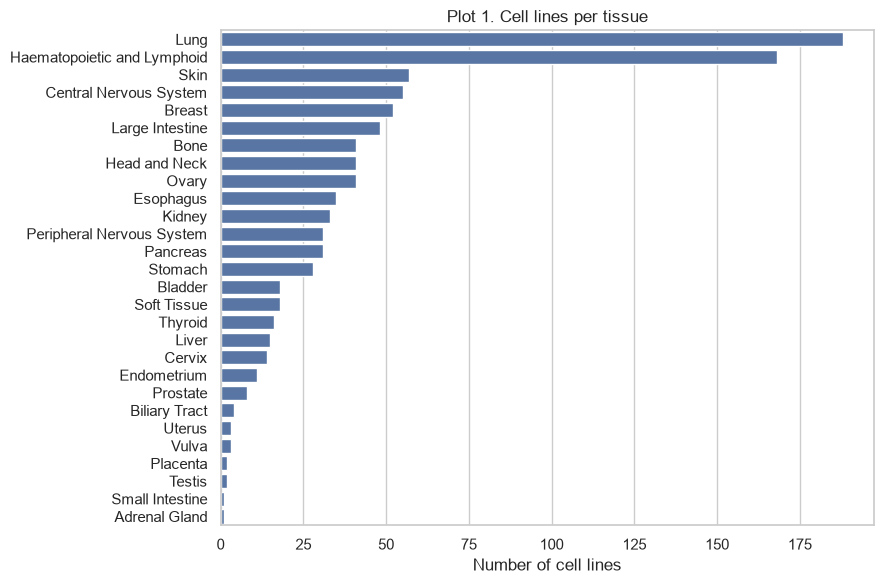

tissue
Lung                           188
Haematopoietic and Lymphoid    168
Skin                            57
Central Nervous System          55
Breast                          52
Large Intestine                 48
Bone                            41
Head and Neck                   41
Ovary                           41
Esophagus                       35
Kidney                          33
Peripheral Nervous System       31
Pancreas                        31
Stomach                         28
Bladder                         18
Soft Tissue                     18
Thyroid                         16
Liver                           15
Cervix                          14
Endometrium                     11
Prostate                         8
Biliary Tract                    4
Uterus                           3
Vulva                            3
Placenta                         2
Testis                           2
Small Intestine                  1
Adrenal Gland                    1


In [6]:
tissue_counts = data.drop_duplicates("SANGER_MODEL_ID")["tissue"].value_counts()

plt.figure(figsize=(9, 6))
sns.barplot(x=tissue_counts.values, y=tissue_counts.index)
plt.xlabel("Number of cell lines")
plt.ylabel("")
plt.title("Plot 1. Cell lines per tissue")
plt.tight_layout()
plt.savefig("figures/plot1_cell_lines_per_tissue.png", dpi=150)
plt.show()

print(tissue_counts.to_string())

Lung (188) and blood cancers (168) make up the largest groups. Breast (52) and large intestine/colorectal (48) also have enough cell lines for case studies. Some tissues have very few cell lines (prostate 8, biliary tract 4), so any result for those tissues on their own won't be reliable.

### Distribution of drug sensitivity (ln IC50)

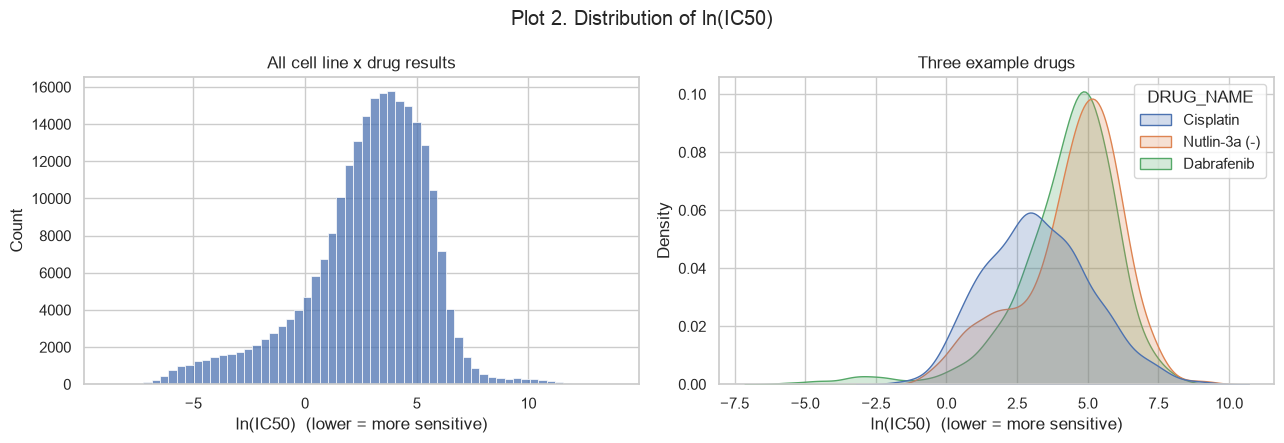

count    241030.00
mean          2.82
std           2.76
min          -8.75
25%           1.51
50%           3.24
75%           4.70
max          13.82
DRUG_NAME
Cisplatin        3.23
Dabrafenib       4.25
Nutlin-3a (-)    4.42
results above the highest tested dose: 71.8 %


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data["LN_IC50"], bins=60, ax=axes[0])
axes[0].set_title("All cell line x drug results")
axes[0].set_xlabel("ln(IC50)  (lower = more sensitive)")

# 1373 = Dabrafenib, 1047 = Nutlin-3a, 1005 = Cisplatin
examples = data[data["DRUG_ID"].isin([1373, 1047, 1005])]
sns.kdeplot(data=examples, x="LN_IC50", hue="DRUG_NAME", fill=True, ax=axes[1])
axes[1].set_title("Three example drugs")
axes[1].set_xlabel("ln(IC50)  (lower = more sensitive)")

fig.suptitle("Plot 2. Distribution of ln(IC50)")
plt.tight_layout()
plt.savefig("figures/plot2_ln_ic50_distribution.png", dpi=150)
plt.show()

print(data["LN_IC50"].describe().round(2).to_string())
print(examples.groupby("DRUG_NAME")["LN_IC50"].mean().round(2).to_string())

# IC50 above the highest tested dose means the value was extrapolated from the fitted curve
above_max = data["LN_IC50"] > np.log(data["MAX_CONC"])
print("results above the highest tested dose:", round(above_max.mean() * 100, 1), "%")

Across 241,030 results, ln(IC50) ranges from about -8.8 to 13.8 with a median of 3.24; the middle half lies between 1.51 and 4.70. Each drug has its own typical range (mean 3.23 for Cisplatin, 4.25 for Dabrafenib, 4.42 for Nutlin-3a) because every drug was tested at its own doses. So raw values shouldn't be compared directly across drugs, and any baseline has to at least predict each drug's average.

In 71.8% of results the IC50 is above the highest dose actually tested, meaning 50% inhibition wasn't reached and the value is an estimate from the fitted curve. We keep these results but treat them as less certain.

### Most frequently mutated genes

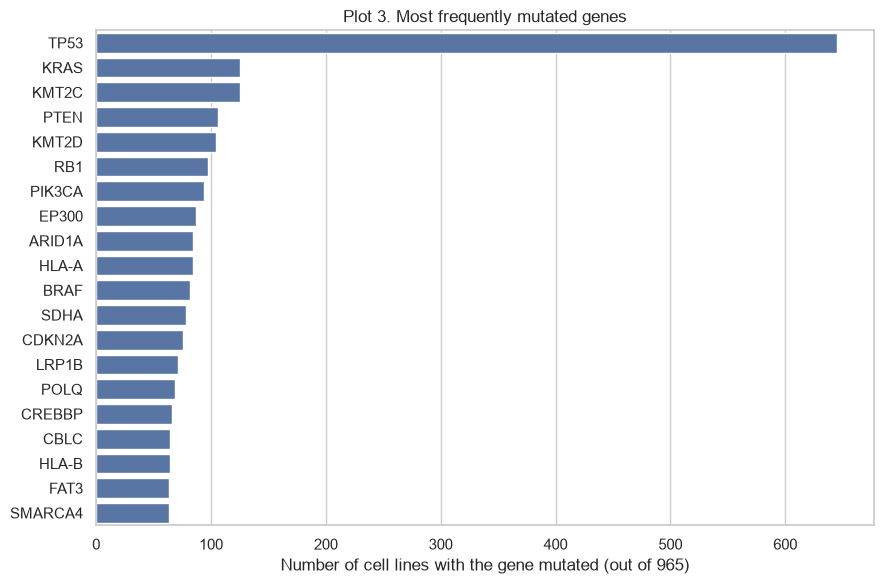

gene_symbol
TP53       645
KRAS       125
KMT2C      125
PTEN       106
KMT2D      104
RB1         97
PIK3CA      94
EP300       87
ARID1A      84
HLA-A       84
BRAF        82
SDHA        78
CDKN2A      76
LRP1B       71
POLQ        69
CREBBP      66
CBLC        64
HLA-B       64
FAT3        63
SMARCA4     63
EGFR: 21
TP53: p.? in 60 of 645 cell lines
KRAS: p.G12D in 32 of 125 cell lines
KMT2C: p.A1685S in 69 of 125 cell lines
PTEN: p.? in 18 of 106 cell lines
KMT2D: p.P2354fs*30 in 7 of 104 cell lines
RB1: p.? in 29 of 97 cell lines
PIK3CA: p.E545K in 22 of 94 cell lines
EP300: p.? in 14 of 87 cell lines
ARID1A: p.D1850fs*4 in 8 of 84 cell lines
HLA-A: p.Q78R in 43 of 84 cell lines
BRAF: p.V600E in 65 of 82 cell lines
SDHA: p.L649fs*4 in 69 of 78 cell lines
CDKN2A: p.R80* in 9 of 76 cell lines
LRP1B: p.? in 22 of 71 cell lines
POLQ: p.V310G in 47 of 69 cell lines
CREBBP: p.? in 11 of 66 cell lines
CBLC: p.Q419fs*81 in 59 of 64 cell lines
HLA-B: p.E69G in 34 of 64 cell lines
FAT3: p.Q

In [8]:
gene_counts = mut_matrix.sum().sort_values(ascending=False)
top20 = gene_counts.head(20)

plt.figure(figsize=(9, 6))
sns.barplot(x=top20.values, y=top20.index)
plt.xlabel(f"Number of cell lines with the gene mutated (out of {len(mut_matrix)})")
plt.ylabel("")
plt.title("Plot 3. Most frequently mutated genes")
plt.tight_layout()
plt.savefig("figures/plot3_mutation_frequency.png", dpi=150)
plt.show()

print(top20.to_string())
print("EGFR:", gene_counts["EGFR"])

# how many cell lines share the single most common change in each gene?
for gene in top20.index:
    changes = mut[mut["gene_symbol"] == gene].drop_duplicates(["model_id", "protein_mutation"])
    top_change = changes["protein_mutation"].value_counts()
    print(f"{gene}: {top_change.index[0]} in {top_change.iloc[0]} of {top20[gene]} cell lines")

TP53 is mutated in 645 of the 965 cell lines, followed by KRAS (125), PTEN (106), PIK3CA (94) and BRAF (82). EGFR is mutated in only 21, so we avoid EGFR-based examples.

Some of these counts are misleading. For SDHA, CBLC, POLQ, KMT2C, HLA-A and HLA-B, most of the "mutations" are the exact same change shared by many unrelated cell lines, which usually points to an inherited variant or a sequencing artefact rather than a cancer mutation. We leave these genes out of the model (section 7).

### Do mutations change drug response?
Two well-known examples: Dabrafenib targets mutated BRAF, so BRAF-mutant cell lines should be more sensitive. Nutlin-3a blocks MDM2, the protein that switches off normal p53, so it should work better when TP53 is *not* mutated.

Dabrafenib - median ln(IC50) by BRAF status:
         count  median
mutated               
no         870    4.71
yes         80    1.61 

Nutlin-3a (-) - median ln(IC50) by TP53 status:
         count  median
mutated               
no         319    2.76
yes        645    5.16 



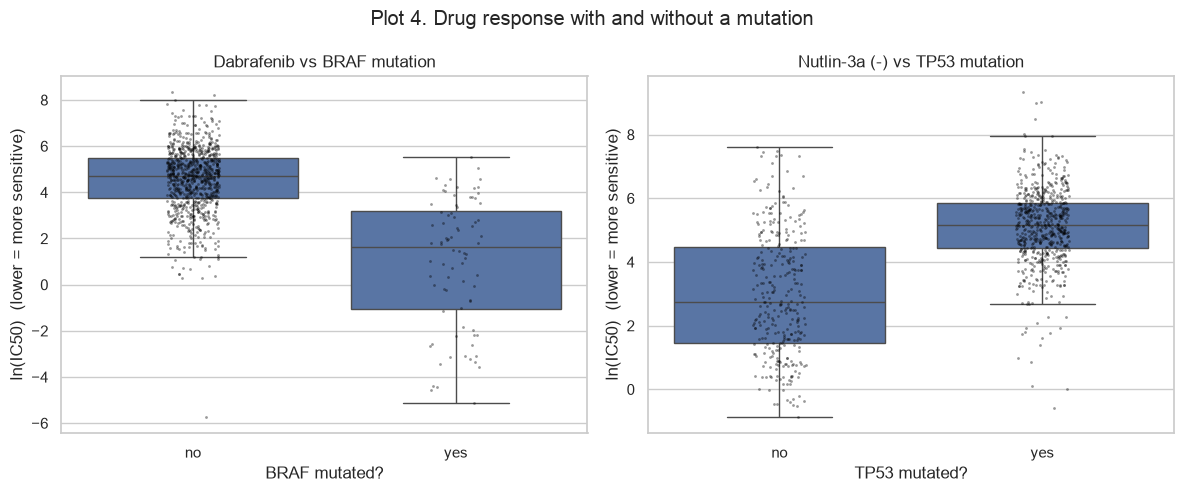

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, drug_id, gene in [(axes[0], 1373, "BRAF"), (axes[1], 1047, "TP53")]:
    d = data[data["DRUG_ID"] == drug_id].copy()
    d["mutated"] = d["SANGER_MODEL_ID"].map(mut_matrix[gene]).map({0: "no", 1: "yes"})
    sns.boxplot(data=d, x="mutated", y="LN_IC50", order=["no", "yes"], showfliers=False, ax=ax)
    sns.stripplot(data=d, x="mutated", y="LN_IC50", order=["no", "yes"], color="black", size=2, alpha=0.4, ax=ax)
    drug = d["DRUG_NAME"].iloc[0]
    ax.set_title(f"{drug} vs {gene} mutation")
    ax.set_xlabel(f"{gene} mutated?")
    ax.set_ylabel("ln(IC50)  (lower = more sensitive)")
    print(drug, f"- median ln(IC50) by {gene} status:")
    print(d.groupby("mutated")["LN_IC50"].agg(["count", "median"]).round(2).to_string(), "\n")

fig.suptitle("Plot 4. Drug response with and without a mutation")
plt.tight_layout()
plt.savefig("figures/plot4_mutation_vs_response.png", dpi=150)
plt.show()

Both examples go in the direction biology predicts. BRAF-mutant cell lines (80) have a median ln(IC50) of 1.61 for Dabrafenib against 4.71 for the other 870. For Nutlin-3a, cell lines without a TP53 mutation (319) have a median of 2.76 against 5.16 for TP53-mutant lines (645).

This is an association in lab data rather than proof of cause, and the groups still overlap, so a single mutation isn't enough to predict response. That is the gap a model combining several genes and the tissue type could help with.

## 7. Exclusions and gene features
We remove the 7 non-cancer cell lines. We also leave out genes where most "mutations" are one identical change shared by many unrelated cell lines (likely inherited variants or sequencing artefacts): the six found in section 6, plus PABPC1 and CLTCL1, which show the same pattern. The loop below prints the evidence. Of the remaining genes, we use those mutated in at least 20 cell lines so each one has enough examples.

In [10]:
columns = ["SANGER_MODEL_ID", "CELL_LINE_NAME", "tissue", "DRUG_ID", "DRUG_NAME", "PUTATIVE_TARGET", "LN_IC50"]
data = data[columns]

non_cancer = models.loc[models["cancer_type"].str.contains("Non-Cancerous", na=False), "model_id"]
data = data[~data["SANGER_MODEL_ID"].isin(non_cancer)].reset_index(drop=True)
mut_matrix = mut_matrix[~mut_matrix.index.isin(non_cancer)]
print("cell lines:", data["SANGER_MODEL_ID"].nunique(), "| results:", len(data))

UNRELIABLE_GENES = ["SDHA", "CBLC", "POLQ", "KMT2C", "HLA-A", "HLA-B", "PABPC1", "CLTCL1"]
# how many cell lines share the single most common change in each gene?
# (DNA-level changes are used here because some protein changes are only recorded as "p.?")
for gene in UNRELIABLE_GENES:
    rows = mutations[(mutations["gene_symbol"] == gene) & mutations["model_id"].isin(mut_matrix.index)]
    rows = rows.drop_duplicates(["model_id", "cdna_mutation"])
    top = rows["cdna_mutation"].value_counts()
    print(f"{gene}: {top.index[0]} in {top.iloc[0]} of {rows['model_id'].nunique()} cell lines")

gene_counts = mut_matrix.sum()
GENES = [g for g in gene_counts.index if gene_counts[g] >= 20 and g not in UNRELIABLE_GENES]
GENES = sorted(GENES, key=lambda g: -gene_counts[g])  # most frequently mutated first
print("\ngene features:", len(GENES))
print(GENES)
print("EGFR is mutated in", gene_counts["EGFR"], "cell lines")

data = data.merge(mut_matrix[GENES], left_on="SANGER_MODEL_ID", right_index=True, how="left")

cell lines: 958 | results: 239081
SDHA: c.1944_1945delTT in 69 of 78 cell lines
CBLC: c.1253_1254insC in 59 of 64 cell lines
POLQ: c.929T>G in 47 of 69 cell lines
KMT2C: c.5053G>T in 69 of 124 cell lines
HLA-A: c.233A>G in 42 of 83 cell lines
HLA-B: c.206A>G in 33 of 63 cell lines
PABPC1: c.999delA in 30 of 38 cell lines
CLTCL1: c.4041+5C>T in 21 of 30 cell lines

gene features: 84
['TP53', 'KRAS', 'PTEN', 'KMT2D', 'RB1', 'PIK3CA', 'EP300', 'ARID1A', 'BRAF', 'CDKN2A', 'LRP1B', 'CREBBP', 'FAT3', 'SMARCA4', 'NRAS', 'NF1', 'RPL22', 'APC', 'FBXW7', 'ACVR2A', 'MSH6', 'SMAD4', 'BAX', 'ZFHX3', 'KMT2B', 'NBEA', 'NIPBL', 'HERC2', 'STK11', 'PIK3R1', 'UBR5', 'BRCA2', 'ATM', 'HSPG2', 'BCORL1', 'CTCF', 'FAT1', 'FAT4', 'SETD2', 'ASXL1', 'CASP8', 'FBN2', 'MLH1', 'PTPRT', 'BIRC6', 'CDH1', 'MGA', 'NF2', 'NFE2L2', 'PBRM1', 'RNF43', 'VHL', 'ARID2', 'BCOR', 'KDM6A', 'TRRAP', 'ARID1B', 'STAG2', 'KEAP1', 'NOTCH1', 'ZNF208', 'ATF7IP', 'BCL9L', 'CRTC1', 'RHOA', 'BRCA1', 'MYH9', 'PARP4', 'PTPN13', 'SPEN', 'MSH

After removing the non-cancer cell lines we have 958 cell lines and 239,081 results. 84 genes pass the filter, from TP53 down to DDX3X. EGFR only just makes it (21 cell lines), so anything involving EGFR rests on few examples.

## 8. Train/test split by cell line
We hold back 20% of the cell lines as a test set. All results for a test cell line stay in the test set, so every score below is measured on cell lines the models have never seen. The test set isn't used for any decisions.

In [11]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(data, groups=data["SANGER_MODEL_ID"]))
train = data.iloc[train_idx]
test = data.iloc[test_idx]

print("train:", train["SANGER_MODEL_ID"].nunique(), "cell lines,", len(train), "results")
print("test: ", test["SANGER_MODEL_ID"].nunique(), "cell lines,", len(test), "results")

overlap = set(train["SANGER_MODEL_ID"]) & set(test["SANGER_MODEL_ID"])
print("cell lines in both sets:", len(overlap))
assert len(overlap) == 0, "a cell line appears in both train and test"

train: 766 cell lines, 191613 results
test:  192 cell lines, 47468 results


cell lines in both sets: 0


## 9. Evaluation metrics
- **RMSE**: the typical size of a prediction error, in ln(IC50) units (lower is better).
- **R²**: the share of all variation that the predictions explain.
- **Within-drug R²**: knowing *which drug* already explains a lot, because drugs differ so much from each other. This score only looks at differences between cell lines for the same drug, which is what tissue and mutations should add. It is measured against each drug's average in the test set, so a method using training-set averages can score slightly below 0.

In [12]:
y_test = test["LN_IC50"]
drug_mean_test = test.groupby("DRUG_ID")["LN_IC50"].transform("mean")

def score(name, pred):
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    # 1 - model error / error of always predicting each drug's test-set average
    within_drug_r2 = 1 - ((y_test - pred) ** 2).sum() / ((y_test - drug_mean_test) ** 2).sum()
    return {"method": name, "RMSE": round(float(rmse), 3), "R2": round(float(r2), 3),
            "within-drug R2": round(float(within_drug_r2), 3)}

results = []

## 10. Baselines
All averages are calculated on the training set only.
1. **Per-drug average**: predict the drug's average ln(IC50).
2. **Per-drug + tissue average**: predict the average for that drug in that tissue, falling back to the drug average when the combination doesn't appear in training.
3. **Linear regression** on drug, tissue and the gene features.

In [13]:
# 1. per-drug average
drug_avg = train.groupby("DRUG_ID")["LN_IC50"].mean()
pred_drug = test["DRUG_ID"].map(drug_avg)
results.append(score("Per-drug average", pred_drug))

# 2. per-drug + tissue average
drug_tissue_avg = train.groupby(["DRUG_ID", "tissue"])["LN_IC50"].mean().rename("avg").reset_index()
pred_drug_tissue = test[["DRUG_ID", "tissue"]].merge(drug_tissue_avg, on=["DRUG_ID", "tissue"], how="left")["avg"]
print("test results without a matching drug + tissue average:", pred_drug_tissue.isna().sum(),
      "| with a tissue never seen in training:", (~test["tissue"].isin(train["tissue"])).sum())
pred_drug_tissue = pred_drug_tissue.fillna(pred_drug.reset_index(drop=True)).values
results.append(score("Per-drug + tissue average", pred_drug_tissue))

# 3. linear regression (drug and tissue one-hot encoded, genes are already 0/1)
encoder = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["DRUG_ID", "tissue"])],
                            remainder="passthrough")
X_train_lr = encoder.fit_transform(train[["DRUG_ID", "tissue"] + GENES])
X_test_lr = encoder.transform(test[["DRUG_ID", "tissue"] + GENES])
linear = LinearRegression().fit(X_train_lr, train["LN_IC50"])
pred_linear = linear.predict(X_test_lr)
results.append(score("Linear regression", pred_linear))

# same linear model without the gene features, for comparison
encoder_ng = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["DRUG_ID", "tissue"])])
linear_ng = LinearRegression().fit(encoder_ng.fit_transform(train[["DRUG_ID", "tissue"]]), train["LN_IC50"])
pred_linear_ng = linear_ng.predict(encoder_ng.transform(test[["DRUG_ID", "tissue"]]))
print("linear regression without genes - within-drug R2:", score("no genes", pred_linear_ng)["within-drug R2"])

pd.DataFrame(results)

test results without a matching drug + tissue average: 551 | with a tissue never seen in training: 534


linear regression without genes - within-drug R2: 0.121


,method,RMSE,R2,within-drug R2
0,Per-drug average,1.464,0.716,-0.007
1,Per-drug + tissue average,1.324,0.768,0.177
2,Linear regression,1.403,0.739,0.076
